# 05 · Models: training, cross-validation, test evaluation (Phase 5)
All syllabus models predict the **temperature anomaly** (truth − external climatology) at 15 depths; prediction = climatology + anomaly.

* **Model selection:** GroupKFold(4) on train months, **groups = month** (whole months held out, never random rows)
* **Test:** the 4 held-out months (Feb, May, Aug, Nov), **identical 200k rows for every model**
* Code: `src/oceanembed_ml/models/` · results: `results/phase5/*.json` (written by `scripts/05_models.py`)

In [1]:
import json, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from oceanembed_ml.config import ROOT, AUDIT, INTERIM, PROCESSED, FINAL, FIGURES, load_yaml
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
print("project root:", ROOT)

project root: D:\Ml project


## 1. Cross-validation (train months only) → chosen hyper-parameters

In [2]:
cv = json.loads((ROOT/"results"/"phase5"/"cv_selection.json").read_text())
pd.DataFrame([{"model": m, "topic": v.get("topic"), "best_params": v.get("best_params", v.get("members")),
               "cv_rmse": v.get("best_cv_rmse"), "fold_std": v.get("best_cv_fold_std")} for m, v in cv.items()]).sort_values("cv_rmse")

,model,topic,best_params,cv_rmse,fold_std
13,ensemble_avg,Ensemble (averaging),"[gradient_boosting, random_forest]",0.577135,NaN
11,gradient_boosting,Boosting (gradient boosting),"{'lr': 0.05, 'leaves': 63}",0.577156,0.021055
10,random_forest,Random Forest (decision forest),{'max_features': 0.66},0.587313,0.020532
12,pca_regression,PCA + Boosting (vertical modes),{'K': 8},0.594428,0.020279
9,bagging_trees,Bagging,{'max_depth': 20},0.597840,0.024015
7,svr_rbf,"SVM (SVR, RBF kernel)",{'C': 1.0},0.618549,0.033195
5,lasso,Lasso (L1),{'alpha': 0.0005},0.626775,0.021842
4,ridge,Ridge (L2),{'alpha': 10.0},0.626780,0.021773
2,linear_regression,Linear Regression (OLS),{},0.626890,0.021836
3,linear_gd_scratch,Gradient descent (from scratch),{'lr': 0.01},0.629324,0.025089


## 2. Test months: all models on the same 200k rows

In [3]:
T = json.loads((ROOT/"results"/"phase5"/"test_metrics.json").read_text())
print("evaluation subset:", T["eval_subset"], "| selected by CV:", T["selected_by_cv"])
tab = pd.DataFrame({m: {"topic": v["topic"], "RMSE": v["overall"]["rmse"], "MAE": v["overall"]["mae"], "bias": v["overall"]["bias"],
                        "R2": v["overall"]["r2"], "r": v["overall"]["pearson_r"], "mean skill vs clim": v["mean_skill_over_depths"],
                        "RMSE@100m": v["per_depth"]["100"]["rmse"], "fit s": v["fit_seconds"], "predict s (200k)": v["predict_seconds_200k"],
                        "train rows": v.get("n_train_rows")} for m, v in T["models"].items()}).T
tab.sort_values("RMSE")

evaluation subset: {'rows': 200000, 'fingerprint': 'bd7624ba0cec7b89', 'months': [2, 5, 8, 11]} | selected by CV: gradient_boosting


,topic,RMSE,MAE,bias,R2,r,mean skill vs clim,RMSE@100m,fit s,predict s (200k),train rows
final_gb_clim_feature,Final: Boosting + climatology feature (CV-sele...,0.57915,0.36996,-0.013904,0.994113,0.997054,0.636461,0.979317,95.4,11.78,400000
ensemble_avg,Ensemble (averaging),0.629248,0.394903,-0.002272,0.99305,0.99652,0.598435,1.104018,490.1,14.99,None
gradient_boosting,Boosting (gradient boosting),0.634252,0.397758,-0.002198,0.992939,0.996465,0.59291,1.117097,102.2,10.74,400000
random_forest,Random Forest (decision forest),0.638668,0.401553,-0.002345,0.99284,0.996415,0.584942,1.1139,387.9,4.25,400000
bagging_trees,Bagging,0.650632,0.407553,-0.00233,0.99257,0.99628,0.571177,1.12927,346.0,7.71,400000
pca_regression,PCA + Boosting (vertical modes),0.653156,0.414577,-0.006682,0.992512,0.996251,0.555777,1.122239,27.2,3.22,400000
svr_rbf,"SVM (SVR, RBF kernel)",0.701951,0.440956,-0.01005,0.991351,0.995669,0.48108,1.241259,69.9,2728.79,10000
knn,KNN,0.721284,0.466882,-0.017139,0.990868,0.995428,0.440405,1.240758,0.5,20.96,150000
ridge,Ridge (L2),0.738027,0.467225,0.017478,0.990439,0.995223,0.452406,1.314138,20.3,1.06,400000
linear_regression,Linear Regression (OLS),0.738046,0.467235,0.01747,0.990439,0.995222,0.45236,1.314196,21.7,1.04,400000


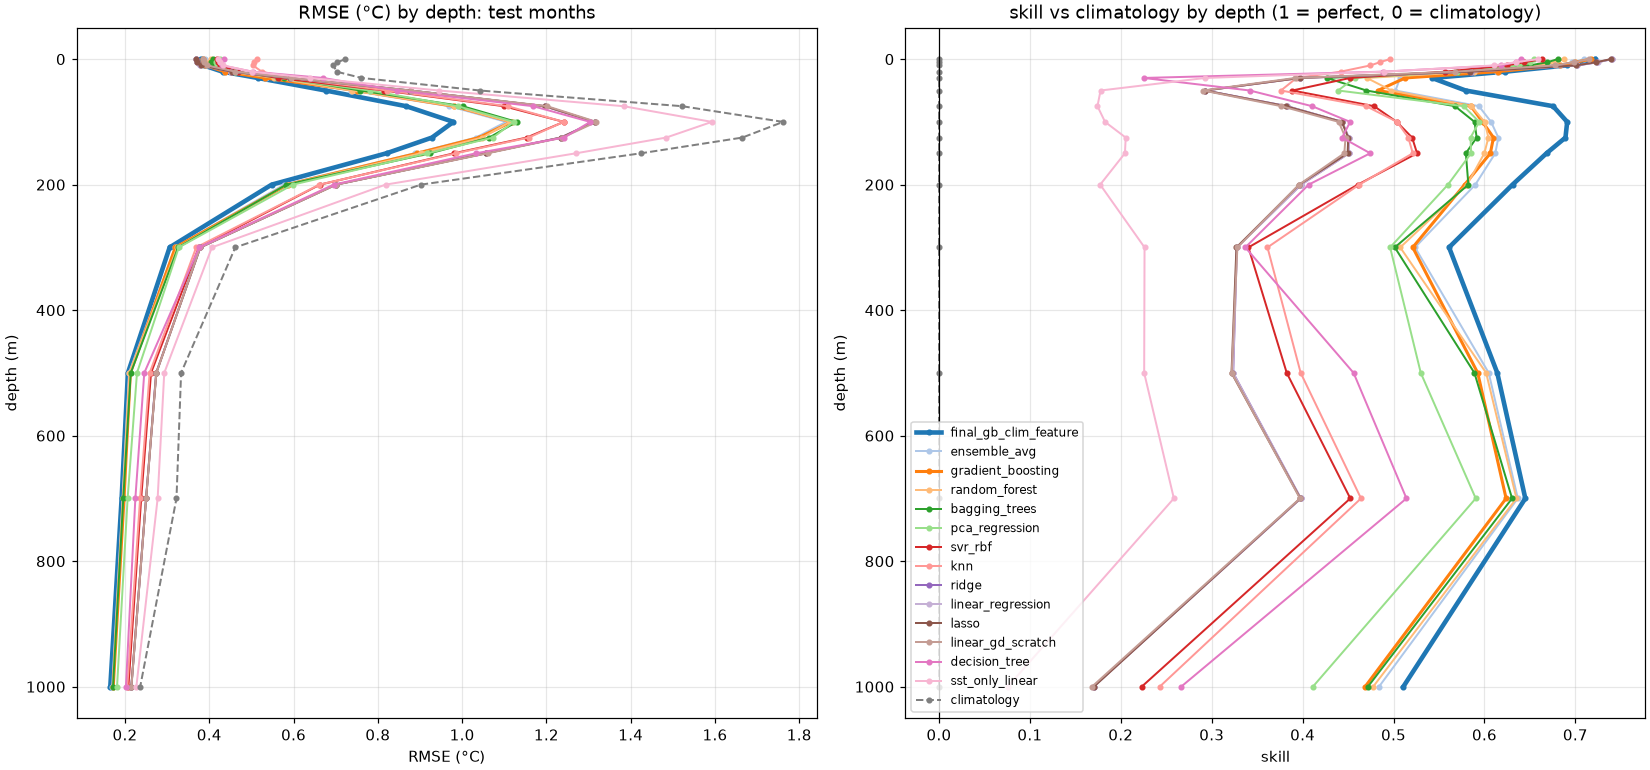

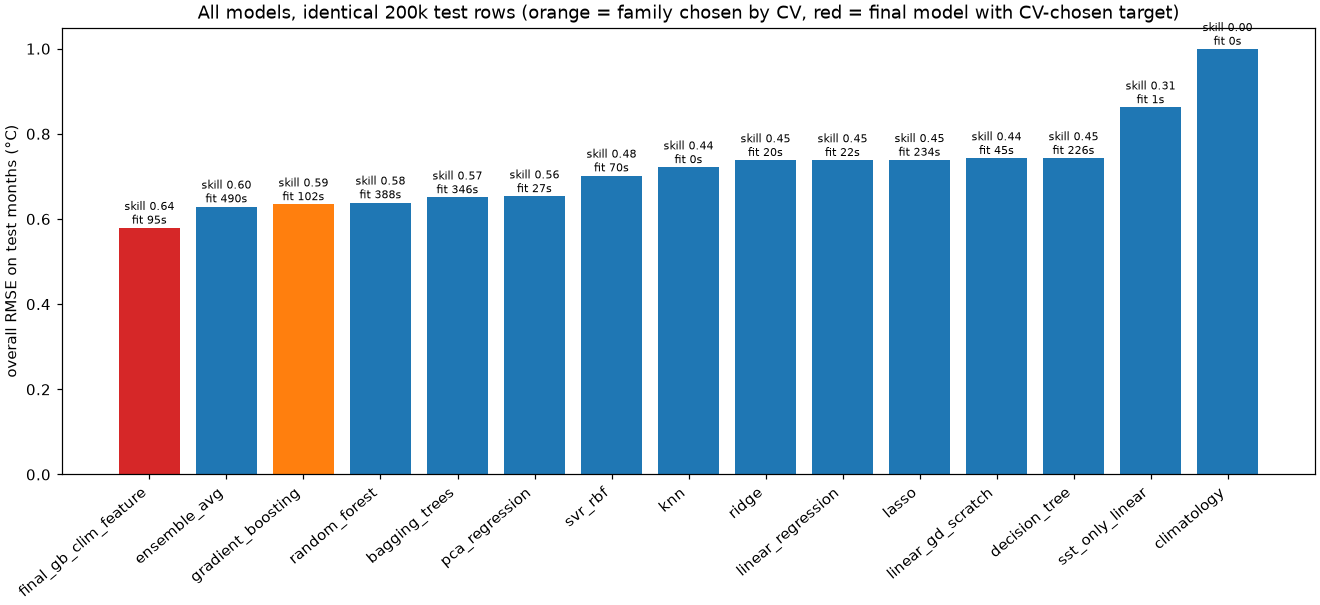

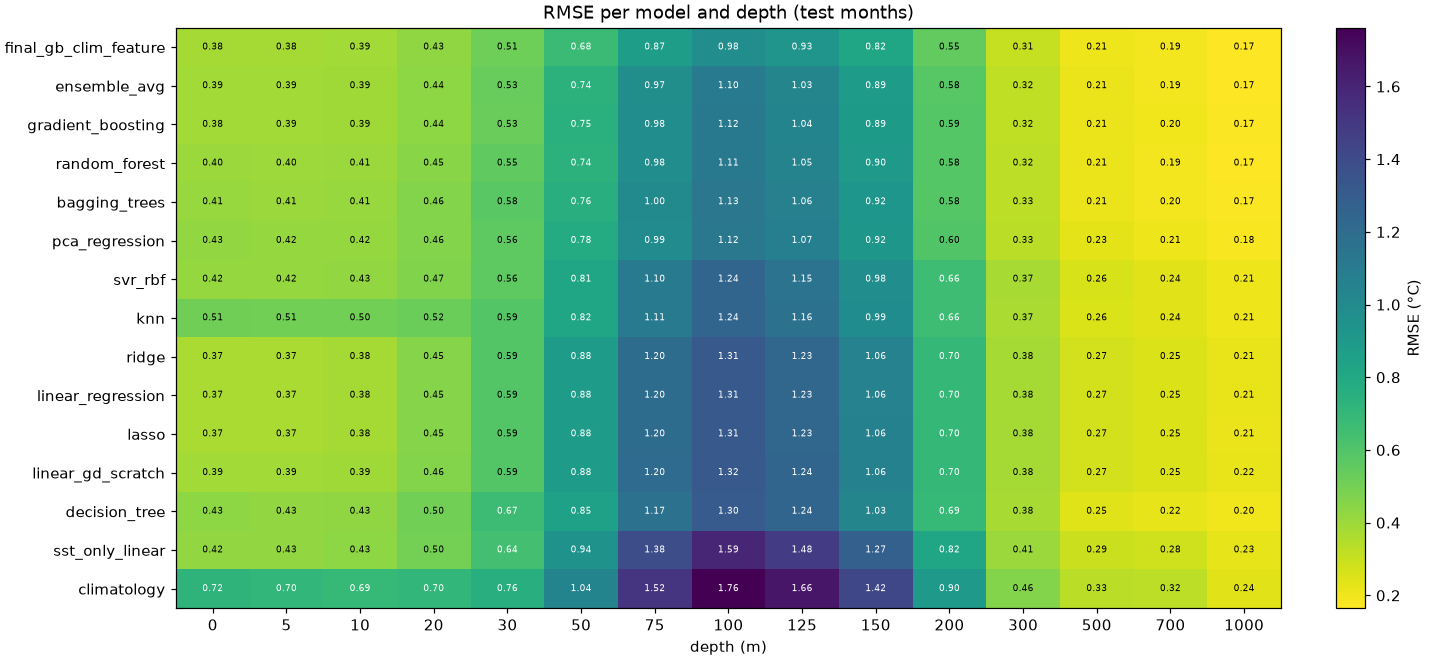

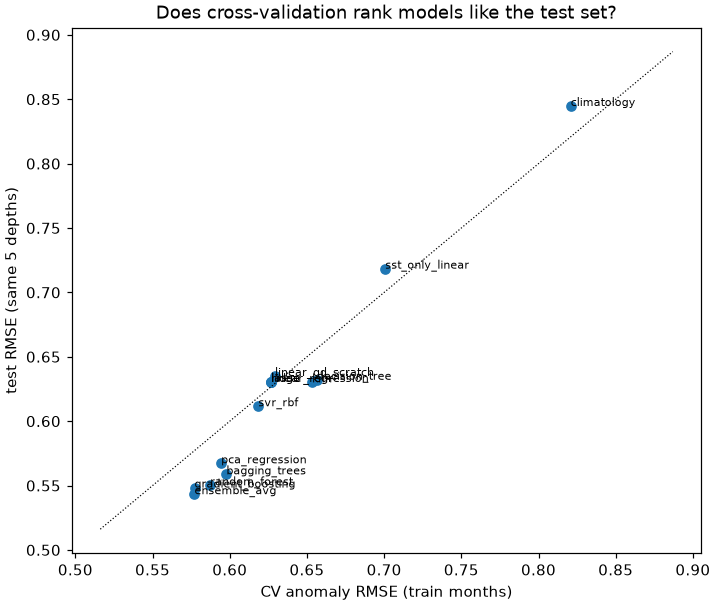

In [4]:
for f in ["01_rmse_skill_by_depth.png","02_overall_comparison.png","03_rmse_heatmap.png","04_cv_vs_test.png"]:
    display(Image(filename=str(FIGURES/"phase5"/f)))

## 3. Best model: regions, seasons, example profiles

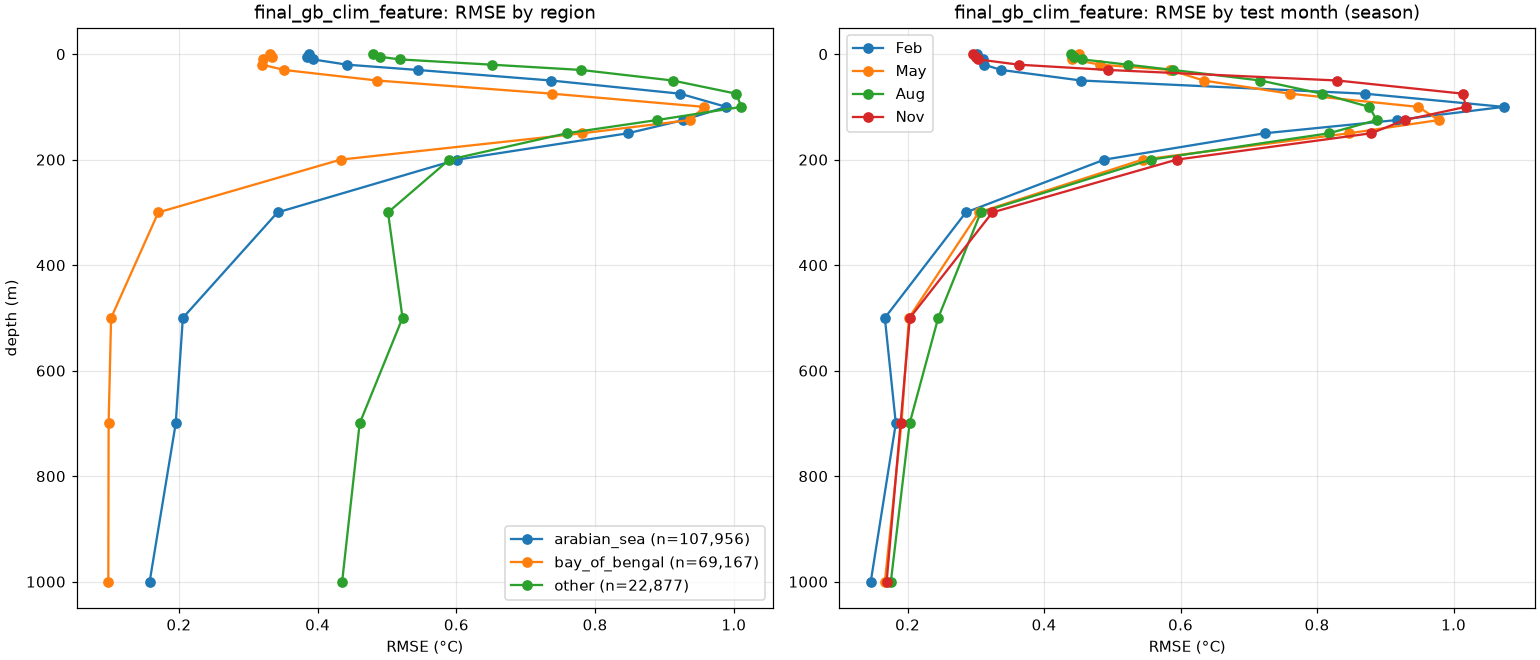

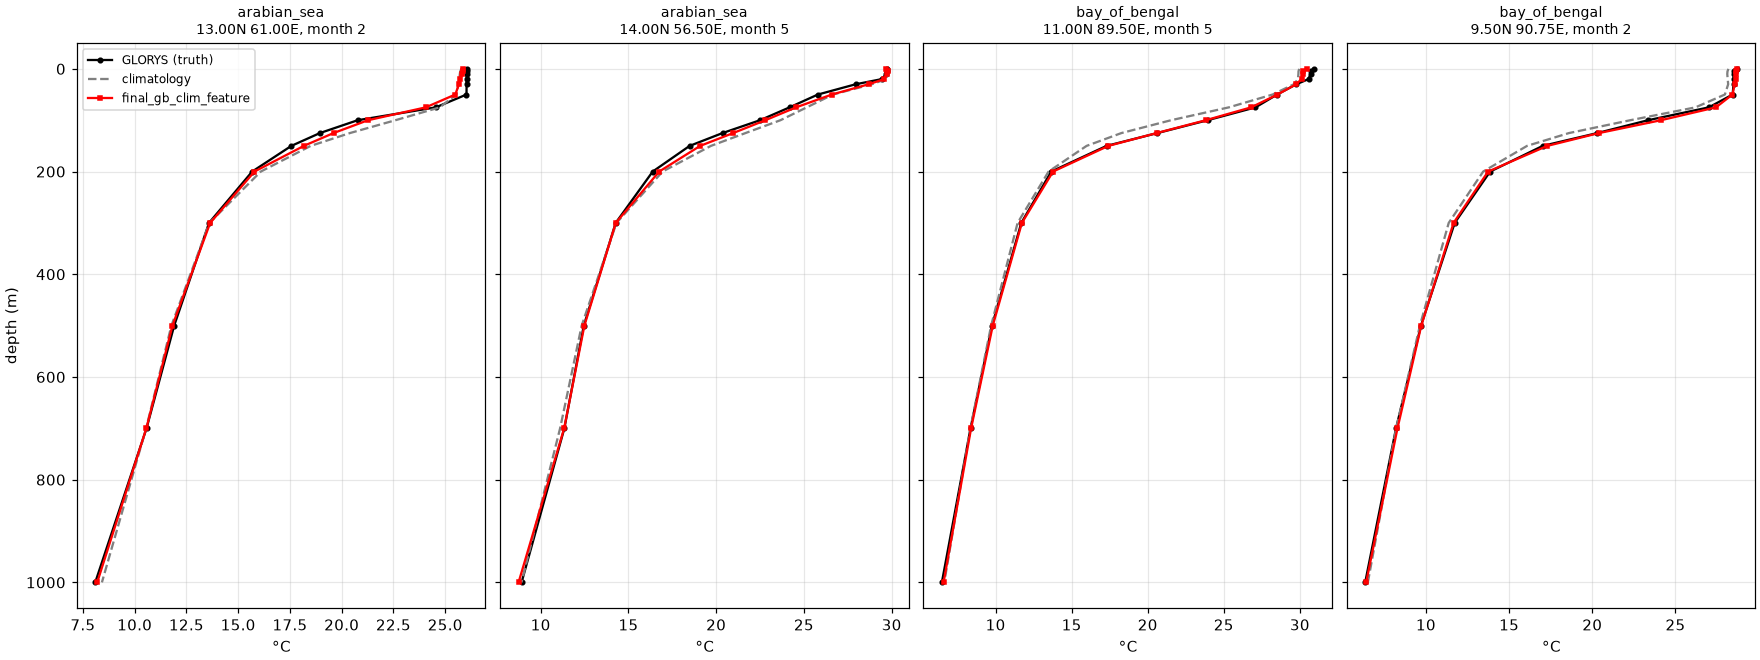

In [5]:
for f in ["05_best_model_region_season.png","06_example_profiles.png"]:
    display(Image(filename=str(FIGURES/"phase5"/f)))

## 4. Linear models: gradient descent from scratch, Ridge, Lasso feature selection

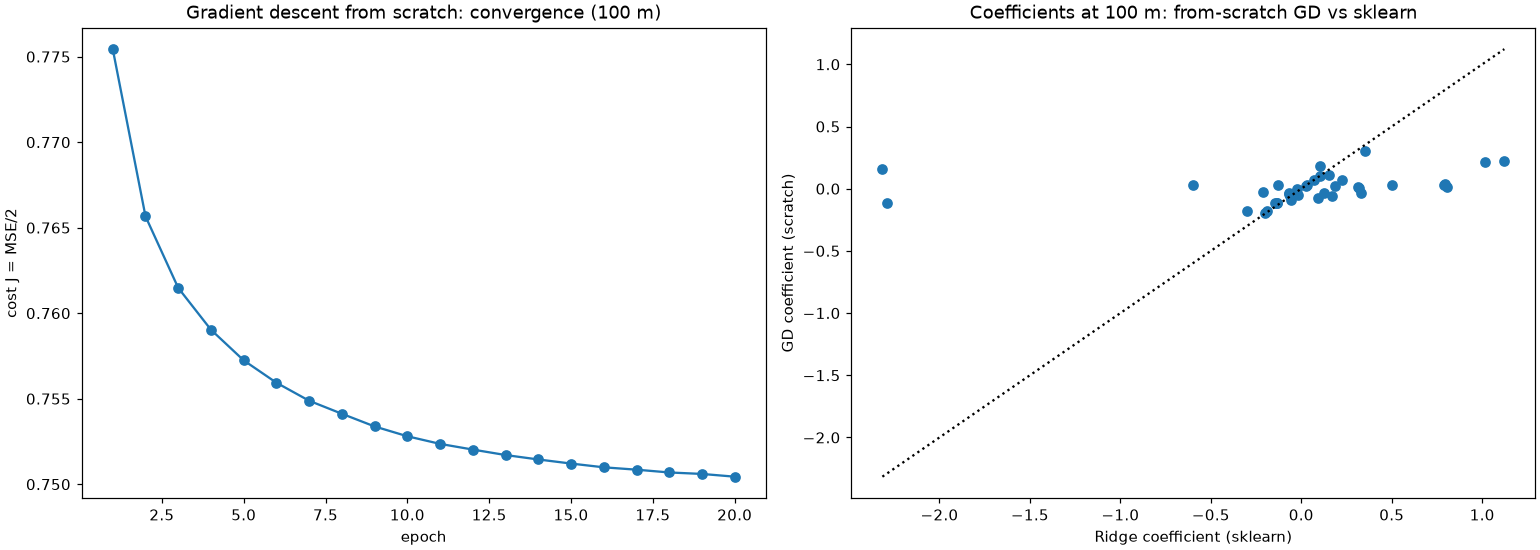

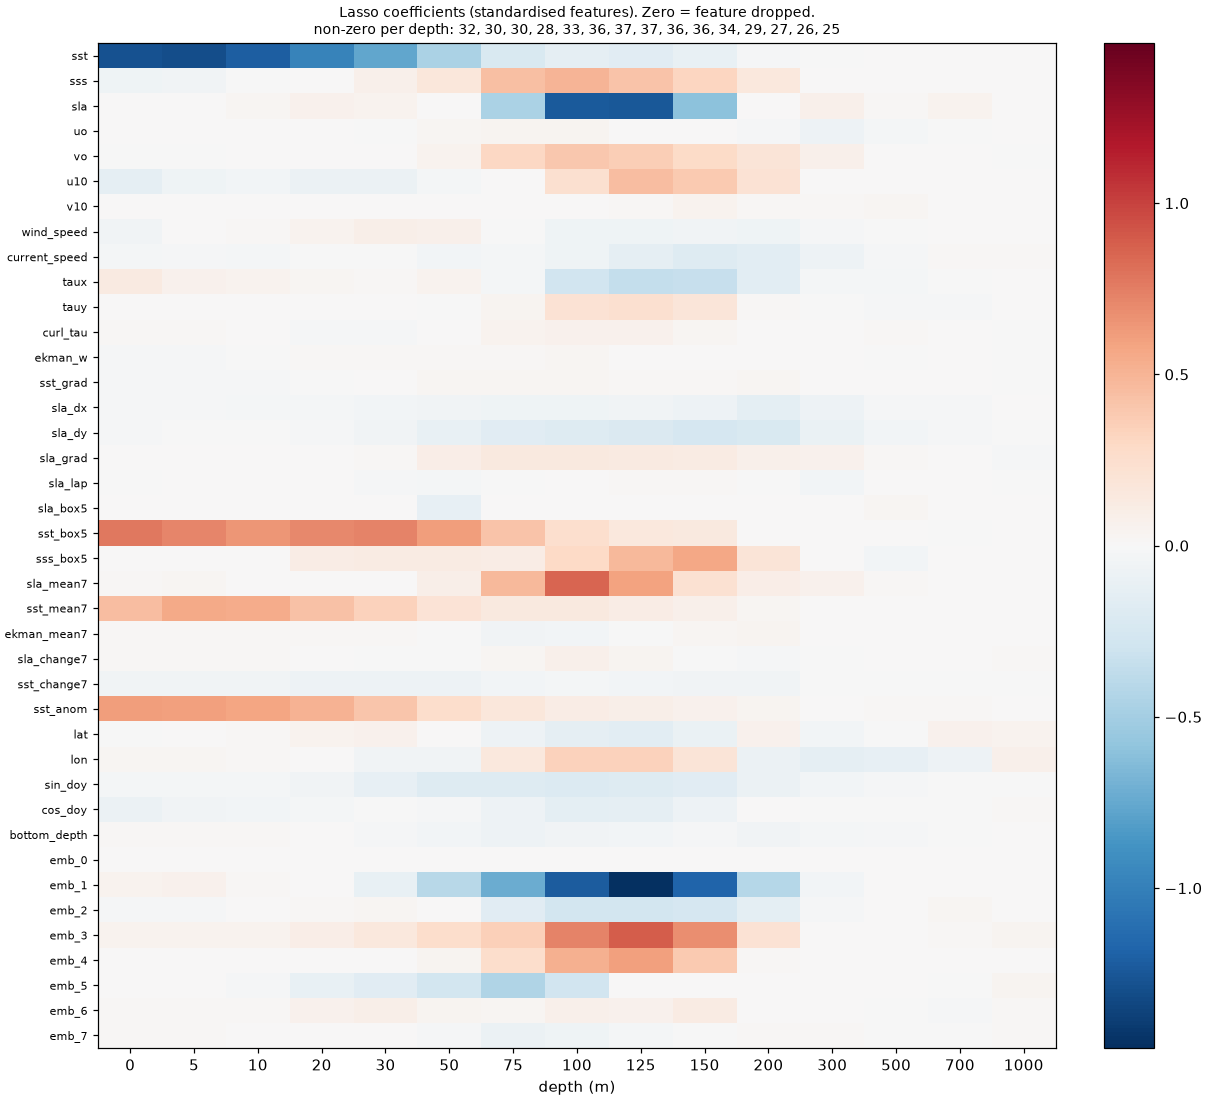

In [6]:
display(Image(filename=str(FIGURES/"phase5"/"07_gradient_descent.png")))
display(Image(filename=str(FIGURES/"phase5"/"08_lasso_coefficients.png")))

## 5. Ablations: feature groups, anomaly vs absolute target, learning curve, group importance

,RMSE,skill,n_features
direct_only (7 raw inputs),0.7872,0.3125,7.0
direct+geo+season,0.6709,0.5092,11.0
all_minus_embedding,0.6337,0.5940,32.0
all_minus_geographic,0.6878,0.5083,38.0
all_minus_temporal,0.6383,0.5849,35.0
all_minus_wind_forcing,0.6338,0.5935,36.0
all_minus_gradients+neighbourhood,0.6351,0.5922,32.0
all (40),0.6343,0.5929,40.0


,RMSE,skill
anomaly (y - climatology),0.6343,0.5929
absolute temperature,0.5857,0.6164
25000 rows,0.6593,0.5568
100000 rows,0.6384,0.5834
400000 rows,0.6343,0.5929


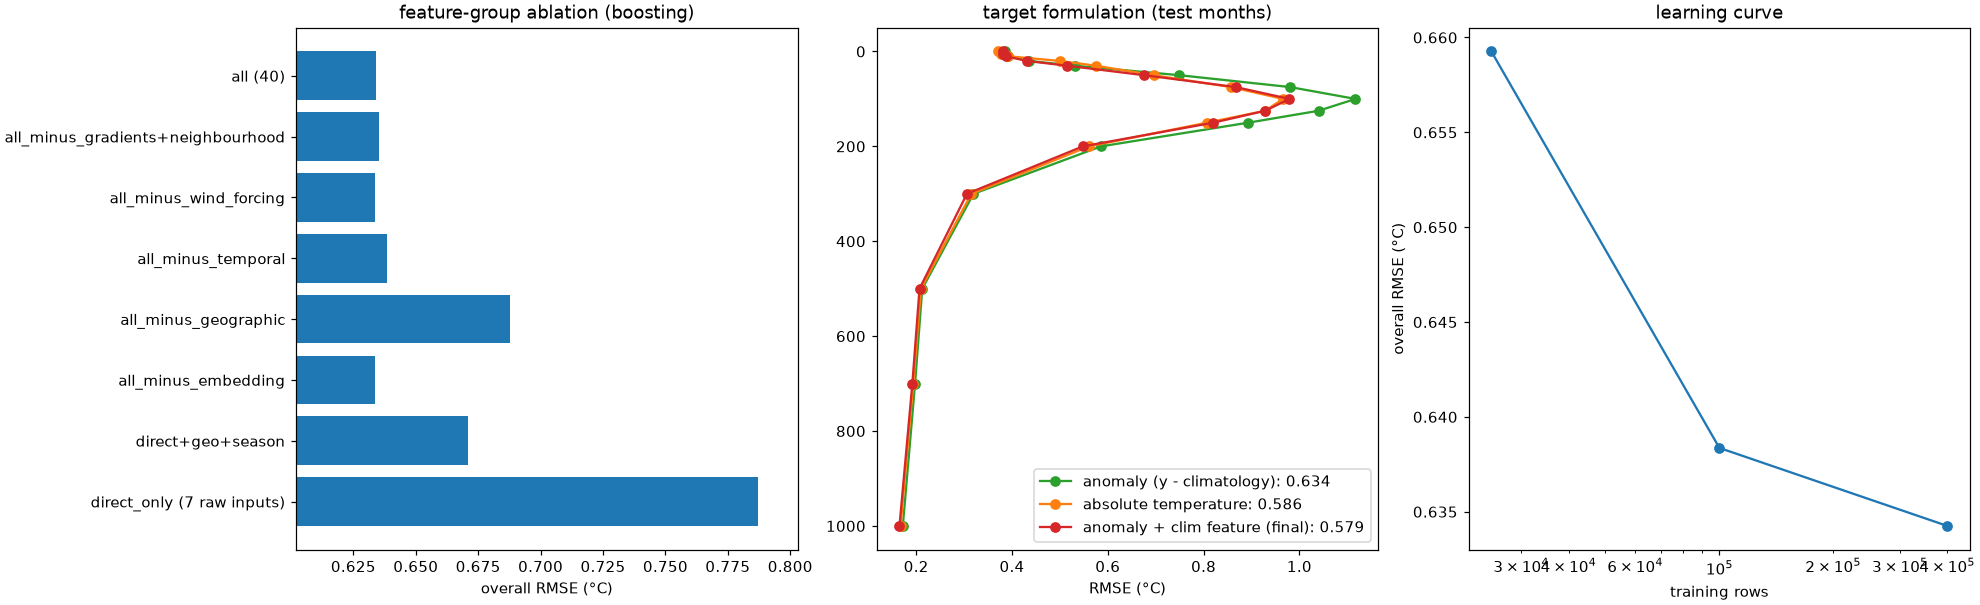

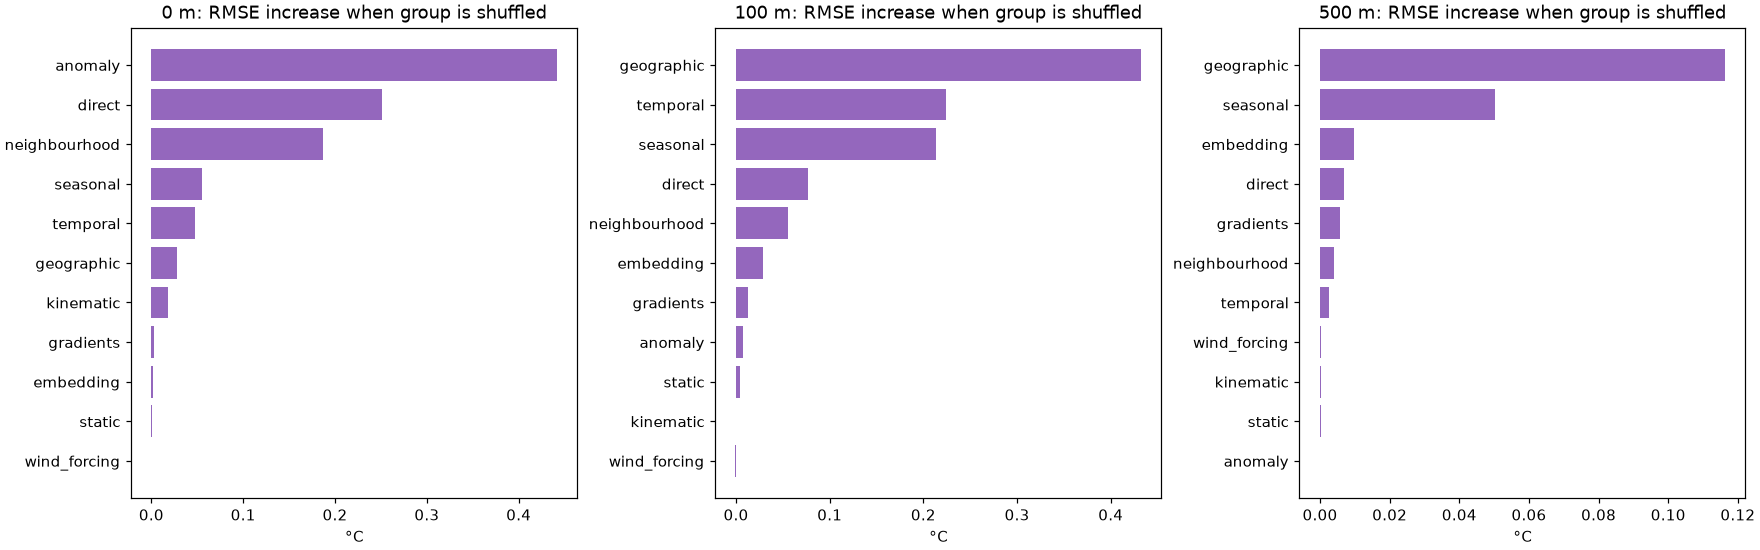

In [7]:
ab = json.loads((ROOT/"results"/"phase5"/"ablation.json").read_text())
display(pd.DataFrame({k: {"RMSE": v["overall_rmse"], "skill": v["mean_skill"], "n_features": v["n_features"]} for k, v in ab["features"].items()}).T.round(4))
display(pd.DataFrame({k: {"RMSE": v["overall_rmse"], "skill": v["mean_skill"]} for k, v in {**ab["target"], **{f"{n} rows": v for n, v in ab["data_size"].items()}}.items()}).T.round(4))
for f in ["09_ablation.png","10_group_permutation_importance.png"]:
    display(Image(filename=str(FIGURES/"phase5"/f)))

## 6. Target formulation decided by cross-validation, and the final model
The test-set ablation hinted that the anomaly target was not optimal, but **test results may not drive choices**, so the
three formulations were compared again with GroupKFold-by-month CV on the train months (`results/phase5/target_cv.json`).

In [8]:
tcv = json.loads((ROOT/"results"/"phase5"/"target_cv.json").read_text())
display(pd.DataFrame({k: {"CV RMSE (abs T)": v["cv_rmse_mean"], "fold std": v["fold_std"], **{f"{d} m": x for d, x in v["per_depth"].items()}}
                      for k, v in tcv["variants"].items()}).T.round(4))
print("selected by CV:", tcv["selected_target"])
fm = json.loads((ROOT/"results"/"phase5"/"final_model.json").read_text())
print(f"FINAL MODEL ({fm['model']}, target={fm['target']}): test RMSE {fm['overall']['rmse']:.3f} °C | MAE {fm['overall']['mae']:.3f} | "
      f"bias {fm['overall']['bias']:.3f} | mean skill {fm['mean_skill_over_depths']:.3f}")
pd.DataFrame(fm["per_depth"]).T[["rmse","mae","bias","r2","pearson_r","skill_vs_clim","n"]].round(3)

,CV RMSE (abs T),fold std,0 m,50 m,100 m,300 m,1000 m
anomaly,0.5772,0.0211,0.4183,0.7722,1.1745,0.3423,0.1786
absolute,0.5562,0.0226,0.3798,0.8058,1.0577,0.3487,0.1892
anomaly+clim_feat,0.5385,0.0210,0.4097,0.7295,1.0489,0.3329,0.1716


selected by CV: anomaly+clim_feat
FINAL MODEL (gradient_boosting (HistGradientBoostingRegressor), one per depth, target=anomaly+clim_feat): test RMSE 0.579 °C | MAE 0.370 | bias -0.014 | mean skill 0.636


,rmse,mae,bias,r2,pearson_r,skill_vs_clim,n
0,0.381,0.272,-0.011,0.958,0.979,0.721,199656.0
5,0.382,0.269,-0.010,0.957,0.979,0.706,199602.0
10,0.386,0.270,-0.006,0.954,0.977,0.690,194733.0
20,0.431,0.295,-0.002,0.942,0.971,0.623,188558.0
30,0.515,0.351,-0.013,0.917,0.958,0.542,184531.0
50,0.676,0.480,-0.046,0.877,0.938,0.579,177144.0
75,0.867,0.639,-0.051,0.841,0.918,0.675,170430.0
100,0.979,0.739,-0.030,0.796,0.893,0.691,166042.0
125,0.928,0.699,-0.013,0.793,0.891,0.689,165318.0
150,0.821,0.601,-0.013,0.829,0.911,0.668,164713.0
